<a href="https://colab.research.google.com/github/claramanolache/DeepLearning/blob/main/Generative_Networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Firewall anylisis
building a model that preforms anomaly detection on network traffic

In [1]:
!pip install opendatasets
!pip install legacy-cgi

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import keras
import torch
import torch.nn as nn
from torch.utils import data

from sklearn import model_selection
from sklearn import ensemble
from sklearn import metrics
from sklearn import dummy

In [9]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

In [10]:
seed = 42
np.random.seed(seed)
torch.manual_seed(seed)

##Helper Functions

In [12]:
def init_params(module):
    if isinstance(module, nn.Linear):
        nn.init.kaiming_uniform_(module.weight)
        nn.init.zeros_(module.bias)

In [46]:
def reconstruction_error(X):
    model.eval()

    with torch.no_grad():
        X = X.to(device)
        reconstructed = model(X)

        errors = torch.mean(
            (X - reconstructed) ** 2,
            dim=1
        )

    return errors.cpu().numpy()

##importing dataset

In [4]:
od.download(
    "https://www.kaggle.com/datasets/tunguz/internet-firewall-data-set")

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: claramanolache
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/tunguz/internet-firewall-data-set


100%|██████████| 754k/754k [00:00<00:00, 80.4MB/s]

In [5]:
import os

folder = "internet-firewall-data-set"

print(os.listdir(folder))

['log2.csv']


In [6]:
file =('internet-firewall-data-set/log2.csv')
df = pds.read_csv(file)

In [7]:
df.shape

(65532, 12)

In [8]:
df.head()

,Source Port,Destination Port,NAT Source Port,NAT Destination Port,Action,Bytes,Bytes Sent,Bytes Received,Packets,Elapsed Time (sec),pkts_sent,pkts_received
0,57222,53,54587,53,allow,177,94,83,2,30,1,1
1,56258,3389,56258,3389,allow,4768,1600,3168,19,17,10,9
2,6881,50321,43265,50321,allow,238,118,120,2,1199,1,1
3,50553,3389,50553,3389,allow,3327,1438,1889,15,17,8,7
4,50002,443,45848,443,allow,25358,6778,18580,31,16,13,18


##Formating/splitting dataset

In [14]:
X = df.drop(columns=["Action"])
actions = df["Action"].copy()

###encoding destination ports by range

In [15]:
df['Destination Port'].nunique()

3273

<Axes: xlabel='Destination Port'>

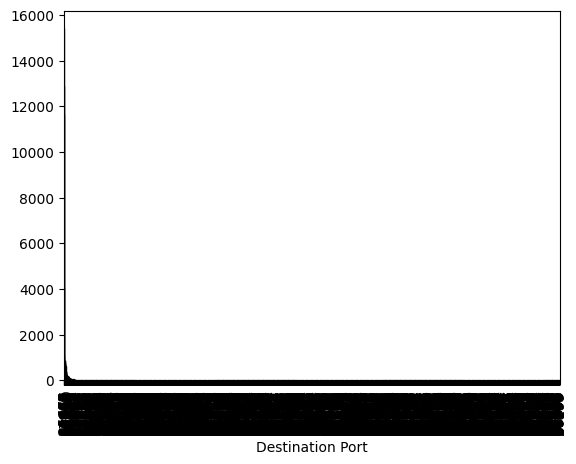

In [16]:
df['Destination Port'].value_counts().plot(kind='bar', color='skyblue', edgecolor='black')

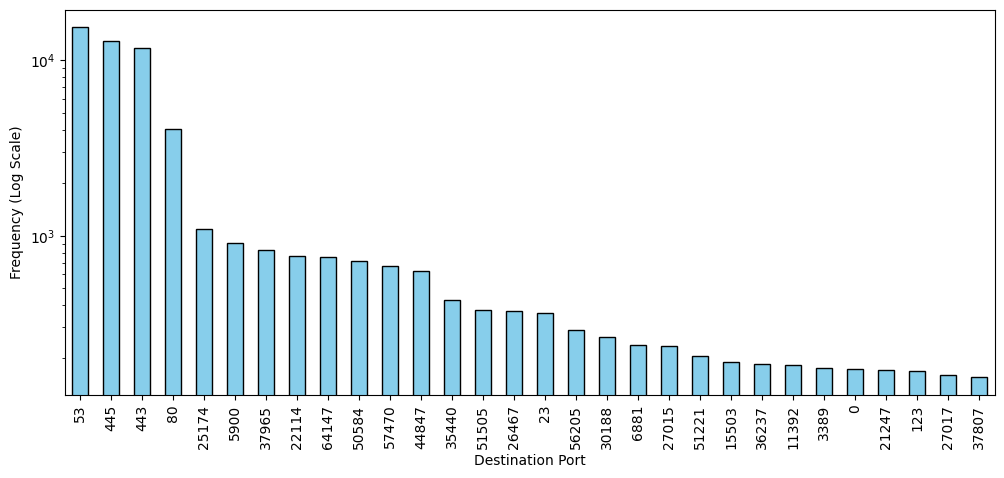

In [17]:
df["Destination Port"].value_counts().head(30).plot(
    kind="bar",
    color="skyblue",
    edgecolor="black",
    figsize=(12, 5),
    logy=True
)

plt.ylabel("Frequency (Log Scale)")
plt.show()

going to encode in ranges

In [18]:
common_ports = (
    X["Destination Port"]
    .value_counts()
    .head(12)
    .index.tolist()
)

In [19]:
def categorize_port(port, common_ports):
    if port in common_ports:
        return str(port)
    elif port == 0:
        return "reserved"
    elif port <= 1023:
        return "well_known"
    elif port <= 49151:
        return "registered"
    else:
        return "dynamic"

In [20]:
X["Destination Port"] = X["Destination Port"].apply(
    lambda port: categorize_port(port, common_ports)
)

In [21]:
X = pd.get_dummies(
    X,
    columns=["Destination Port"],
    dtype=float
)

In [22]:
X.head()

,Source Port,NAT Source Port,NAT Destination Port,Bytes,Bytes Sent,Bytes Received,Packets,Elapsed Time (sec),pkts_sent,pkts_received,...,Destination Port_50584,Destination Port_53,Destination Port_57470,Destination Port_5900,Destination Port_64147,Destination Port_80,Destination Port_dynamic,Destination Port_registered,Destination Port_reserved,Destination Port_well_known
0,57222,54587,53,177,94,83,2,30,1,1,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,56258,56258,3389,4768,1600,3168,19,17,10,9,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,6881,43265,50321,238,118,120,2,1199,1,1,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,50553,50553,3389,3327,1438,1889,15,17,8,7,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,50002,45848,443,25358,6778,18580,31,16,13,18,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [24]:
X.shape

(65532, 26)

###Encoding source ports

In [25]:
df['Source Port'].nunique()

22724

In [26]:
common_source_ports = (
    X["Source Port"]
    .value_counts()
    .head(12)
    .index.tolist()
)

X["Source Port"] = X["Source Port"].apply(
    lambda port: categorize_port(port, common_source_ports)
)

X = pd.get_dummies(
    X,
    columns=["Source Port"],
    dtype=float
)

X.head()

,NAT Source Port,NAT Destination Port,Bytes,Bytes Sent,Bytes Received,Packets,Elapsed Time (sec),pkts_sent,pkts_received,Destination Port_22114,...,Source Port_443,Source Port_49418,Source Port_50584,Source Port_5588,Source Port_57470,Source Port_58638,Source Port_6881,Source Port_dynamic,Source Port_registered,Source Port_well_known
0,54587,53,177,94,83,2,30,1,1,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,56258,3389,4768,1600,3168,19,17,10,9,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,43265,50321,238,118,120,2,1199,1,1,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,50553,3389,3327,1438,1889,15,17,8,7,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,45848,443,25358,6778,18580,31,16,13,18,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


###Encode NAF

In [32]:
X["NAT Source Changed"] = (
    df["Source Port"] != df["NAT Source Port"]
).astype(int)

X["NAT Destination Changed"] = (
    df["Destination Port"] != df["NAT Destination Port"]
).astype(int)

In [34]:
common_nat_ports = (
    X["NAT Destination Port"]
    .value_counts()
    .head(12)
    .index.tolist()
)

X["NAT Destination Port"] = X["NAT Destination Port"].apply(
    lambda port: categorize_port(port, common_nat_ports)
)

X["NAT Source Port"] = X["NAT Source Port"].apply(
    lambda port: categorize_port(port, [])
)

X = pd.get_dummies(
    X,
    columns=["NAT Source Port", "NAT Destination Port"],
    dtype=float
)

In [33]:
X.head()

,NAT Source Port,NAT Destination Port,Bytes,Bytes Sent,Bytes Received,Packets,Elapsed Time (sec),pkts_sent,pkts_received,Destination Port_22114,...,Source Port_50584,Source Port_5588,Source Port_57470,Source Port_58638,Source Port_6881,Source Port_dynamic,Source Port_registered,Source Port_well_known,NAT Source Changed,NAT Destination Changed
0,54587,53,177,94,83,2,30,1,1,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1,0
1,56258,3389,4768,1600,3168,19,17,10,9,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0,0
2,43265,50321,238,118,120,2,1199,1,1,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1,0
3,50553,3389,3327,1438,1889,15,17,8,7,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0,0
4,45848,443,25358,6778,18580,31,16,13,18,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1,0


###rest of splitting

In [30]:
import pandas as pd
from sklearn.model_selection import train_test_split

y_labels = (actions != 'allow').astype(int)

X_sub = X.iloc[:20000].copy()
y_sub = y_labels.iloc[:20000].copy()

normal_indices = y_sub[y_sub == 0].index
anomaly_indices = y_sub[y_sub == 1].index

train_normal_idx, rem_normal_idx = train_test_split(
    normal_indices,
    test_size=0.40,
    random_state=seed
)

X_train = X_sub.loc[train_normal_idx]
y_train = y_sub.loc[train_normal_idx]

mixed_rem_idx = rem_normal_idx.union(anomaly_indices)
X_rem = X_sub.loc[mixed_rem_idx]
y_rem = y_sub.loc[mixed_rem_idx]

X_val, X_test, y_val, y_test = train_test_split(
    X_rem, y_rem,
    test_size=0.5,
    random_state=seed,
    stratify=y_rem
)

print(f"Training set (Normal only): {X_train.shape}, {y_train.value_counts().to_dict()}")
print(f"Validation set (Mixed): {X_val.shape}, {y_val.value_counts().to_dict()}")
print(f"Test set (Mixed): {X_test.shape}, {y_test.value_counts().to_dict()}")

Training set (Normal only): (6611, 40), {0: 6611}
Validation set (Mixed): (6694, 40), {1: 4490, 0: 2204}
Test set (Mixed): (6695, 40), {1: 4491, 0: 2204}


In [31]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [38]:
train_loader = data.DataLoader(
    data.TensorDataset(
        torch.FloatTensor(X_train)
    ),
    batch_size=32,
    shuffle=True
)

X_val = torch.FloatTensor(X_val)
X_test = torch.FloatTensor(X_test)

##Autencoder/Decoder shapes

In [39]:
input_dim = X_train.shape[1]
print(input_dim)

40


In [40]:
latent_dim = 4

encoder = nn.Sequential(
    nn.Linear(input_dim, 32),
    nn.ReLU(),
    nn.Linear(32, 16),
    nn.ReLU(),
    nn.Linear(16, latent_dim)
)

In [41]:
decoder = nn.Sequential(
    nn.Linear(latent_dim, 16),
    nn.ReLU(),
    nn.Linear(16, 32),
    nn.ReLU(),
    nn.Linear(32, input_dim)
)

In [42]:
model = nn.Sequential(
    encoder,
    decoder
).apply(init_params)

model = model.to(device)

##Hyperparams

In [43]:
n_epochs = 30
learning_rate = 0.001

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate
)

criterion = nn.MSELoss()

##Training

In [44]:
X_val_normal = X_val[y_val == 0]

train_losses = []
val_losses = []

for epoch in range(n_epochs):

    model.train()
    total_loss = 0

    for (X_batch,) in train_loader:

        X_batch = X_batch.to(device)

        optimizer.zero_grad()

        reconstructed = model(X_batch)
        loss = criterion(reconstructed, X_batch)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * X_batch.size(0)

    train_loss = total_loss / len(X_train)
    train_losses.append(train_loss)

    model.eval()

    with torch.no_grad():
        val_batch = X_val_normal.to(device)
        reconstructed_val = model(val_batch)

        val_loss = criterion(
            reconstructed_val,
            val_batch
        ).item()

    val_losses.append(val_loss)

    print(
        f"Epoch {epoch+1}/{n_epochs} | "
        f"Train: {train_loss:.6f} | "
        f"Val: {val_loss:.6f}"
    )

Epoch 1/30 | Train: 0.047695 | Val: 0.018806
Epoch 2/30 | Train: 0.012006 | Val: 0.006896
Epoch 3/30 | Train: 0.004798 | Val: 0.003544
Epoch 4/30 | Train: 0.003074 | Val: 0.002572
Epoch 5/30 | Train: 0.002206 | Val: 0.001912
Epoch 6/30 | Train: 0.001786 | Val: 0.001667
Epoch 7/30 | Train: 0.001598 | Val: 0.001526
Epoch 8/30 | Train: 0.001464 | Val: 0.001405
Epoch 9/30 | Train: 0.001353 | Val: 0.001294
Epoch 10/30 | Train: 0.001256 | Val: 0.001189
Epoch 11/30 | Train: 0.001150 | Val: 0.001078
Epoch 12/30 | Train: 0.001039 | Val: 0.000983
Epoch 13/30 | Train: 0.000961 | Val: 0.000925
Epoch 14/30 | Train: 0.000887 | Val: 0.000825
Epoch 15/30 | Train: 0.000809 | Val: 0.000785
Epoch 16/30 | Train: 0.000756 | Val: 0.000736
Epoch 17/30 | Train: 0.000711 | Val: 0.000672
Epoch 18/30 | Train: 0.000667 | Val: 0.000624
Epoch 19/30 | Train: 0.000620 | Val: 0.000593
Epoch 20/30 | Train: 0.000596 | Val: 0.000556
Epoch 21/30 | Train: 0.000561 | Val: 0.000522
Epoch 22/30 | Train: 0.000533 | Val: 0.0005

##Results/graphs

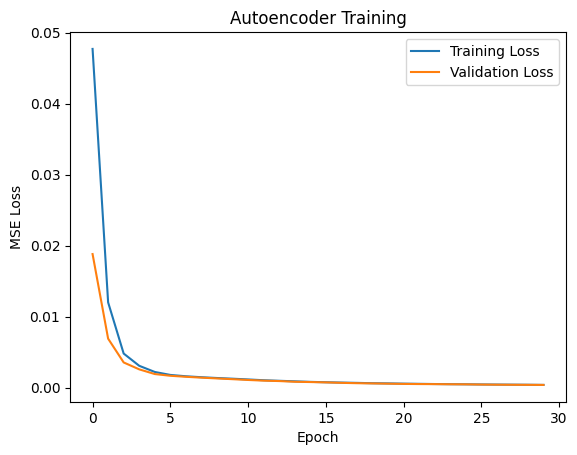

In [45]:
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training")
plt.legend()
plt.show()

In [47]:
val_errors = reconstruction_error(X_val_normal)

threshold = np.percentile(val_errors, 95)

print("Anomaly threshold:", threshold)

Anomaly threshold: 0.000490875


In [48]:
test_errors = reconstruction_error(X_test)

y_pred = (test_errors > threshold).astype(int)

In [49]:
print(metrics.classification_report(
    y_test,
    y_pred,
    target_names=["Allow", "Non-Allow"]
))

              precision    recall  f1-score   support

       Allow       1.00      0.94      0.97      2204
   Non-Allow       0.97      1.00      0.99      4491

    accuracy                           0.98      6695
   macro avg       0.99      0.97      0.98      6695
weighted avg       0.98      0.98      0.98      6695



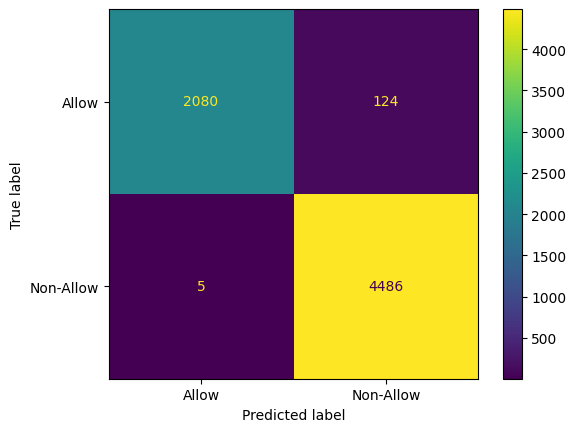

In [50]:
metrics.ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Allow", "Non-Allow"]
)

plt.show()

In [51]:
auc = metrics.roc_auc_score(y_test, test_errors)
print("ROC-AUC:", auc)

ROC-AUC: 0.9926503541464862


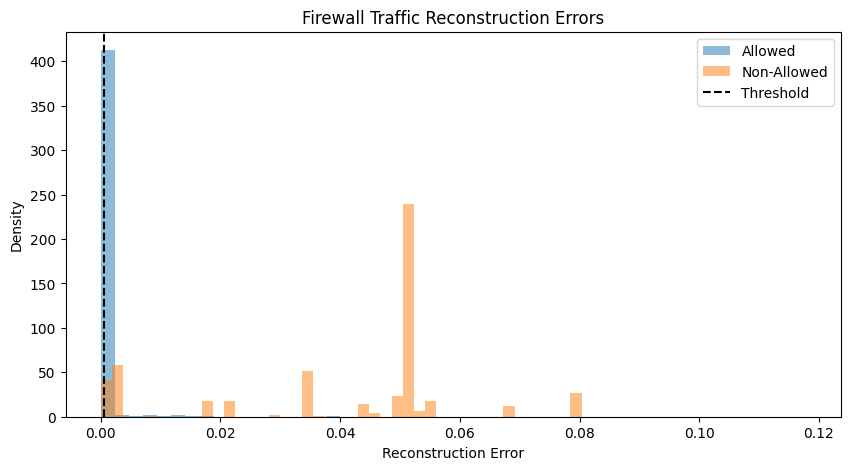

In [52]:
plt.figure(figsize=(10, 5))

plt.hist(
    test_errors[y_test == 0],
    bins=50,
    alpha=0.5,
    density=True,
    label="Allowed"
)

plt.hist(
    test_errors[y_test == 1],
    bins=50,
    alpha=0.5,
    density=True,
    label="Non-Allowed"
)

plt.axvline(
    threshold,
    color="black",
    linestyle="--",
    label="Threshold"
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Density")
plt.title("Firewall Traffic Reconstruction Errors")
plt.legend()
plt.show()